In [30]:
import numpy as np
from helpers import *
from implementations import *
import csv
import matplotlib.pyplot as plt

In [18]:
x_train, x_test, y_train, train_ids, test_ids= load_csv_data("dataset/") ####DO NOT RERUNNNNNNNNNN!!!!!!

In [ ]:
X = np.nan_to_num(x_train, nan=0)
y = (y_train + 1) / 2

indices = np.random.default_rng(42).permutation(len(y))
split = int(0.8 * len(y))
tr, val = indices[:split], indices[split:]

X_tr, X_val = X[tr], X[val]
y_tr, y_val = y[tr], y[val]

mean = X_tr.mean(axis=0)
std = X_tr.std(axis=0)
std[std == 0] = 1

X_tr = (X_tr - mean) / std
X_val = (X_val - mean) / std
x_test_scaled = (np.nan_to_num(x_test, nan=0) - mean) / std

X_tr = np.column_stack((np.ones(len(X_tr)), X_tr))
X_val = np.column_stack((np.ones(len(X_val)), X_val))
x_test_scaled = np.column_stack((np.ones(len(x_test_scaled)), x_test_scaled))

In [58]:
def sigmoid(t):
    t = np.clip(t, -500, 500)
    return 1 / (1 + np.exp(-t))

In [19]:
with open("dataset/x_train.csv") as f:
    feature_names = next(csv.reader(f))[1:]
feature_names

['_STATE',
 'FMONTH',
 'IDATE',
 'IMONTH',
 'IDAY',
 'IYEAR',
 'DISPCODE',
 'SEQNO',
 '_PSU',
 'CTELENUM',
 'PVTRESD1',
 'COLGHOUS',
 'STATERES',
 'CELLFON3',
 'LADULT',
 'NUMADULT',
 'NUMMEN',
 'NUMWOMEN',
 'CTELNUM1',
 'CELLFON2',
 'CADULT',
 'PVTRESD2',
 'CCLGHOUS',
 'CSTATE',
 'LANDLINE',
 'HHADULT',
 'GENHLTH',
 'PHYSHLTH',
 'MENTHLTH',
 'POORHLTH',
 'HLTHPLN1',
 'PERSDOC2',
 'MEDCOST',
 'CHECKUP1',
 'BPHIGH4',
 'BPMEDS',
 'BLOODCHO',
 'CHOLCHK',
 'TOLDHI2',
 'CVDSTRK3',
 'ASTHMA3',
 'ASTHNOW',
 'CHCSCNCR',
 'CHCOCNCR',
 'CHCCOPD1',
 'HAVARTH3',
 'ADDEPEV2',
 'CHCKIDNY',
 'DIABETE3',
 'DIABAGE2',
 'SEX',
 'MARITAL',
 'EDUCA',
 'RENTHOM1',
 'NUMHHOL2',
 'NUMPHON2',
 'CPDEMO1',
 'VETERAN3',
 'EMPLOY1',
 'CHILDREN',
 'INCOME2',
 'INTERNET',
 'WEIGHT2',
 'HEIGHT3',
 'PREGNANT',
 'QLACTLM2',
 'USEEQUIP',
 'BLIND',
 'DECIDE',
 'DIFFWALK',
 'DIFFDRES',
 'DIFFALON',
 'SMOKE100',
 'SMOKDAY2',
 'STOPSMK2',
 'LASTSMK2',
 'USENOW3',
 'ALCDAY5',
 'AVEDRNK2',
 'DRNK3GE5',
 'MAXDRNKS',
 'FRUITJU

In [33]:
def logistic_regressionsium(y, tx, initial_w, max_iters, gamma):
    """Train a logistic regression model using gradient descent.

    Parameters
    ----------
    y : np.ndarray
        Binary target values of shape (n_samples,), usually 0 or 1.
    tx : np.ndarray
        Feature matrix of shape (n_samples, n_features).
    initial_w : np.ndarray
        Initial weight vector of shape (n_features,).
    max_iters : int
        Number of gradient descent iterations.
    gamma : float
        Learning rate used to update the weights.

    Returns
    -------
    w : np.ndarray
        Final learned weight vector of shape (n_features,).
    final_loss : float
        Logistic loss after the final iteration.

    Example
    -------
    y = np.array([0, 1, 1])
    tx = np.array([[0.2, 1.0], [1.0, 0.8], [1.5, 1.2]])
    w0 = np.array([0.0, 0.0])
    w, loss = logistic_regression(y, tx, w0, 200, 0.1)

    Example of use
    --------------
    weights, train_loss = logistic_regression(y_train, tx_train, w_init, 500, 0.01)
    """
    w = initial_w
    losses=[]
    for i in range(max_iters):
        z = tx @ w
        sigma = np.exp(-np.logaddexp(0, -z))
        gradient = tx.T @ (sigma - y) / len(y)
        w = w - gamma * gradient
        if i%10==0:
            z = tx @ w
            loss = np.sum(np.logaddexp(0, z) - y * z) / len(y)
            losses.append(loss)
    return (w, losses)

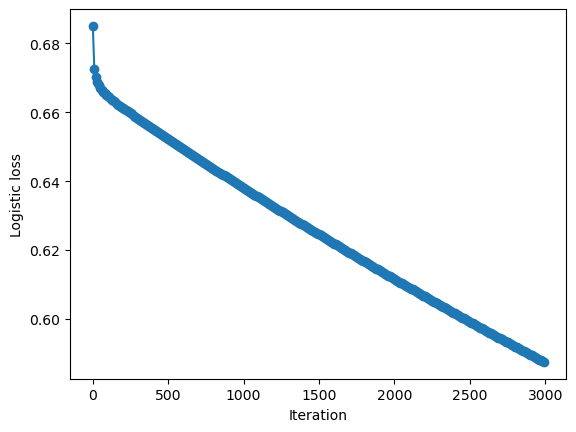

In [ ]:
w, losses = logistic_regressionsium(
    y_train_0,
    x_train_scaled,
    np.zeros(x_train_scaled.shape[1]),
    3000,
    0.1
)

plt.plot(np.arange(len(losses)) * 10, losses, marker="o")
plt.xlabel("Iteration")
plt.ylabel("Logistic loss")
plt.show()



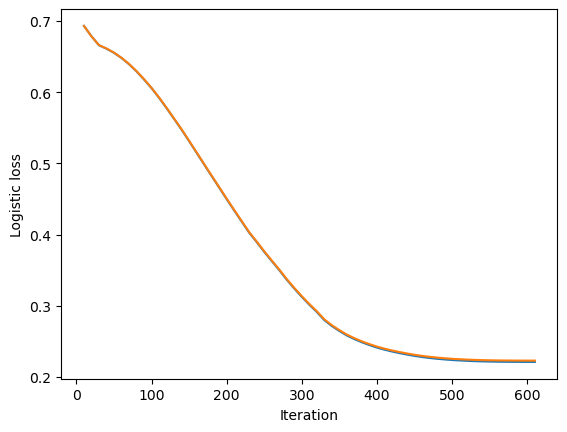

In [85]:
def logistic_loss(y, X, w):
    z = X @ w
    return np.mean(np.logaddexp(0, z) - y * z)


def logistic_gradient(y, X, w):
    z = X @ w
    p = np.exp(-np.logaddexp(0, -z))  # stable sigmoid
    return X.T @ (p - y) / len(y)


def LS_AGDR_initialize(initial_w, initial_L=1.0):
    w = initial_w.copy()
    return (w, 1.0, w.copy(), initial_L)  # x_k, t_k, y_k, L_k



def LS_AGDR_update(X_tr, X_val, y_tr, y_val, state,train_losses, val_losses, iter):

    x_k, t_k, y_k, Lk0 = state
    L_kprev = Lk0
    Lk0 = Lk0 / 2

    dk = -logistic_gradient(y_tr, X_tr, y_k)
    i = 0

    while logistic_loss(y_tr, X_tr, y_k + (1 / (Lk0 * 2**i)) * dk) > \
          logistic_loss(y_tr, X_tr, y_k) - (1 / (Lk0 * 2**(i + 1))) * np.linalg.norm(dk)**2:
        i += 1

    Lk = Lk0 * 2**i
    alpha_k = 1 / Lk

    prov_next_x_k = y_k - alpha_k * logistic_gradient(y_tr, X_tr, y_k)

    if logistic_loss(y_tr, X_tr, prov_next_x_k) > logistic_loss(y_tr, X_tr, x_k):
        y_k = x_k
        t_k = 1
        i = 0
        dk = -logistic_gradient(y_tr, X_tr, y_k)

        while logistic_loss(y_tr, X_tr, y_k + (1 / (Lk0 * 2**i)) * dk) > \
              logistic_loss(y_tr, X_tr, y_k) - (1 / (Lk0 * 2**(i + 1))) * np.linalg.norm(dk)**2:
            i += 1

        Lk = Lk0 * 2**i
        alpha_k = 1 / Lk

    x_next = y_k - alpha_k * logistic_gradient(y_tr, X_tr, y_k)

    t_next = (1 + np.sqrt(1 + 4 * Lk / L_kprev * t_k**2)) / 2
    y_next = x_next + ((t_k - 1) / t_next) * (x_next - x_k)

    if iter % 10 == 0:
        train_losses.append(logistic_loss(y_tr, X_tr, x_next))
        val_losses.append(logistic_loss(y_val, X_val, x_next))

    return (x_next, t_next, y_next, Lk)




w0 = np.zeros(X_tr.shape[1])
losses_tr = [logistic_loss(y_tr, X_tr, w0)]
losses_val=[logistic_loss(y_val,X_val,w0)]
state = LS_AGDR_initialize(w0)

for i in range(600):
    state = LS_AGDR_update(X_tr,X_val,y_tr,y_val,state,losses_tr,losses_val,i)

w = state[0]

iterations = 10 * np.arange(1, len(losses_tr) + 1)
plt.plot(iterations, losses_tr)
plt.plot(iterations, losses_val)
plt.xlabel("Iteration")
plt.ylabel("Logistic loss")
plt.show()

In [88]:
losses_val[-1]

0.22302634777068073

In [89]:
losses_tr[-1]

0.22117243417132926

In [56]:
print(len(X_tr))

262508


In [57]:
print(len(X_tr[0]))

321


In [91]:
def find_best_tresh():
    list=[0.2]
    bestf1=0
    best_tresh=0
    for tresh in list:
    ###COMPUTING CONFUSION MATRIX for y_val
        y_val_pred = (sigmoid(X_val @ w) >= tresh).astype(int)

        tn = np.sum((y_val == 0) & (y_val_pred == 0))
        fp = np.sum((y_val == 0) & (y_val_pred == 1))
        fn = np.sum((y_val == 1) & (y_val_pred == 0))
        tp = np.sum((y_val == 1) & (y_val_pred == 1))

        confusion_matrix = np.array([[tn, fp],
                                    [fn, tp]])

        print(confusion_matrix)  # rows: actual, columns: predicted
        print("Accuracy:", np.mean(y_val_pred == y_val))
        f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0.0
        print("F1 score:", f1)
        if f1>bestf1:
            bestf1=f1
            best_tresh=tresh
    return best_tresh,bestf1

best_tresh,bestf1=find_best_tresh()
print(best_tresh,bestf1)

[[53958  5844]
 [ 2717  3108]]
Accuracy: 0.8695506422661404
F1 score: 0.4206537186167693
0.2 0.4206537186167693


In [92]:
predicted_probs=sigmoid(x_test_scaled@w)
y_pred=np.where(predicted_probs>0.2,1,-1)
idx = np.loadtxt("dataset/x_test.csv", delimiter=",", skiprows=1, usecols=0)
create_csv_submission(idx,y_pred,"submission.csv")





### PART2: WEIGHTED

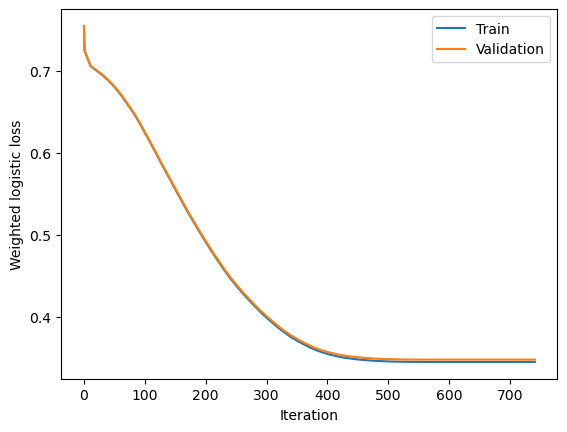

In [97]:
n = len(y_tr)
weight_0 = 1
weight_1 = 2

def logistic_loss_weighted(y, X, w):
    z = X @ w
    weights = np.where(y == 1, weight_1, weight_0)
    return np.mean(weights * (np.logaddexp(0, z) - y * z))


def logistic_gradient_weighted(y, X, w):
    z = X @ w
    p = np.exp(-np.logaddexp(0, -z))
    weights = np.where(y == 1, weight_1, weight_0)
    return X.T @ (weights * (p - y)) / len(y)


def LS_AGDR_initialize(initial_w, initial_L=1.0):
    w = initial_w.copy()
    return (w, 1.0, w.copy(), initial_L)  # x_k, t_k, y_k, L_k



def LS_AGDR_update_weighted(X_tr, X_val, y_tr, y_val, state,train_losses, val_losses, iter):

    x_k, t_k, y_k, Lk0 = state
    L_kprev = Lk0
    Lk0 = Lk0 / 2

    dk = -logistic_gradient_weighted(y_tr, X_tr, y_k)
    i = 0

    while logistic_loss_weighted(y_tr, X_tr, y_k + (1 / (Lk0 * 2**i)) * dk) > \
          logistic_loss_weighted(y_tr, X_tr, y_k) - (1 / (Lk0 * 2**(i + 1))) * np.linalg.norm(dk)**2:
        i += 1

    Lk = Lk0 * 2**i
    alpha_k = 1 / Lk

    prov_next_x_k = y_k - alpha_k * logistic_gradient_weighted(y_tr, X_tr, y_k)

    if logistic_loss_weighted(y_tr, X_tr, prov_next_x_k) > logistic_loss_weighted(y_tr, X_tr, x_k):
        y_k = x_k
        t_k = 1
        i = 0
        dk = -logistic_gradient_weighted(y_tr, X_tr, y_k)

        while logistic_loss_weighted(y_tr, X_tr, y_k + (1 / (Lk0 * 2**i)) * dk) > \
              logistic_loss_weighted(y_tr, X_tr, y_k) - (1 / (Lk0 * 2**(i + 1))) * np.linalg.norm(dk)**2:
            i += 1

        Lk = Lk0 * 2**i
        alpha_k = 1 / Lk

    x_next = y_k - alpha_k * logistic_gradient_weighted(y_tr, X_tr, y_k)

    t_next = (1 + np.sqrt(1 + 4 * Lk / L_kprev * t_k**2)) / 2
    y_next = x_next + ((t_k - 1) / t_next) * (x_next - x_k)

    if iter % 10 == 0:
        train_losses.append(logistic_loss_weighted(y_tr, X_tr, x_next))
        val_losses.append(logistic_loss_weighted(y_val, X_val, x_next))

    return (x_next, t_next, y_next, Lk)




w0_weighted = np.zeros(X_tr.shape[1])

losses_tr_weighted = [logistic_loss_weighted(y_tr, X_tr, w0_weighted)]
losses_val_weighted = [logistic_loss_weighted(y_val, X_val, w0_weighted)]
state_weighted = LS_AGDR_initialize(w0_weighted)

for i in range(750):
    state_weighted = LS_AGDR_update_weighted(
        X_tr, X_val, y_tr, y_val,
        state_weighted,
        losses_tr_weighted, losses_val_weighted,
        i
    )

w_weighted = state_weighted[0]

iterations = np.r_[0, 1 + 10 * np.arange(len(losses_tr_weighted) - 1)]

plt.plot(iterations, losses_tr_weighted, label="Train")
plt.plot(iterations, losses_val_weighted, label="Validation")
plt.xlabel("Iteration")
plt.ylabel("Weighted logistic loss")
plt.legend()
plt.show()

In [98]:
losses_tr_weighted[-1]

0.3452260896586943

In [99]:
losses_val_weighted[-1]

0.34807611026063967

In [101]:
def find_best_tresh_w():
    list=np.linspace(0.3,1,11)
    bestf1=0
    best_tresh=0
    for tresh in list:
    ###COMPUTING CONFUSION MATRIX for y_val
        y_val_pred_w = (sigmoid(X_val @ w_weighted) >= tresh).astype(int)

        tn = np.sum((y_val == 0) & (y_val_pred_w == 0))
        fp = np.sum((y_val == 0) & (y_val_pred_w == 1))
        fn = np.sum((y_val == 1) & (y_val_pred_w == 0))
        tp = np.sum((y_val == 1) & (y_val_pred_w == 1))

        confusion_matrix = np.array([[tn, fp],
                                    [fn, tp]])

        print(confusion_matrix)  # rows: actual, columns: predicted
        print("tresh : ",tresh)
        print("Accuracy:", np.mean(y_val_pred_w == y_val))
        f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0.0
        print("F1 score:", f1)
        if f1>bestf1:
            bestf1=f1
            best_tresh=tresh
    return best_tresh,bestf1

best_tresh_w,bestf1_w=find_best_tresh_w()
print(best_tresh_w,bestf1_w)

[[52692  7110]
 [ 2400  3425]]
tresh :  0.3
Accuracy: 0.8550901305864964
F1 score: 0.4187041564792176
[[54977  4825]
 [ 2993  2832]]
tresh :  0.37
Accuracy: 0.8808722019900346
F1 score: 0.420115709835336
[[56618  3184]
 [ 3556  2269]]
tresh :  0.43999999999999995
Accuracy: 0.8972983680497356
F1 score: 0.4023763078560028
[[57805  1997]
 [ 4079  1746]]
tresh :  0.51
Accuracy: 0.9074161549362305
F1 score: 0.3649665551839465
[[58624  1178]
 [ 4539  1286]]
tresh :  0.58
Accuracy: 0.9128864644125131
F1 score: 0.31029074677283147
[[59174   628]
 [ 4987   838]]
tresh :  0.6499999999999999
Accuracy: 0.9144407027595349
F1 score: 0.22987244548072966
[[59527   275]
 [ 5284   541]]
tresh :  0.72
Accuracy: 0.9152940100873116
F1 score: 0.16292726998945942
[[59710    92]
 [ 5503   322]]
tresh :  0.7899999999999999
Accuracy: 0.914745455376598
F1 score: 0.10322167013944543
[[59785    17]
 [ 5619   206]]
tresh :  0.8599999999999999
Accuracy: 0.9141207125116186
F1 score: 0.06812169312169312
[[59800     2]

### PART3 RIDGE & better feature selection